In [1]:
!git clone https://github.com/memuna-javedd/sports-equipment-condition-classifier.git
%cd sports-equipment-condition-classifier
!ls data

Cloning into 'sports-equipment-condition-classifier'...
remote: Enumerating objects: 300, done.
remote: Counting objects: 100% (300/300), done.
remote: Compressing objects: 100% (298/298), done.
remote: Total 300 (delta 3), reused 291 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (300/300), 17.58 MiB | 23.04 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/sports-equipment-condition-classifier
train  val


In [2]:
import torch, torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import numpy as np
from sklearn.metrics import (precision_recall_curve, average_precision_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)])

val_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)])

train_ds = datasets.ImageFolder("data/train", train_tf)
val_ds   = datasets.ImageFolder("data/val", val_tf)
train_dl = DataLoader(train_ds, batch_size=16, shuffle=True)
val_dl   = DataLoader(val_ds, batch_size=16)

print(train_ds.class_to_idx, len(train_ds), len(val_ds))

Using: cpu
{'damaged': 0, 'functional': 1} 220 56


In [3]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# freeze everything: the model keeps what it already knows
for p in model.parameters():
    p.requires_grad = False

# new last layer: gives 2 answers (damaged / functional)
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(device)

# class weights: handles imbalance (the brief asks for this)
counts = np.bincount(train_ds.targets)
weights = torch.tensor(len(train_ds) / (2 * counts), dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=weights)
print("class weights:", weights)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 279MB/s]


class weights: tensor([1., 1.])


In [4]:
def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, probs, labels = 0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.set_grad_enabled(train):
            out = model(x)
            loss = criterion(out, y)
            if train:
                opt.zero_grad()
                loss.backward()
                opt.step()
        total_loss += loss.item() * len(x)
        probs += torch.softmax(out, 1)[:, 0].detach().cpu().tolist()  # chance of "damaged"
        labels += y.cpu().tolist()
    return total_loss / len(loader.dataset), np.array(probs), np.array(labels)

train_losses, val_losses = [], []
best_f1 = 0

# Round 1: train only the new last layer
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
for epoch in range(5):
    tl, _, _ = run_epoch(train_dl, True)
    vl, vp, vy = run_epoch(val_dl, False)
    f1 = f1_score(vy == 0, vp > 0.5)
    train_losses.append(tl); val_losses.append(vl)
    print(f"Round 1 - epoch {epoch+1}: train loss {tl:.3f}, val loss {vl:.3f}, val F1 {f1:.3f}")
    if f1 > best_f1:
        best_f1 = f1
        torch.save(model.state_dict(), "resnet18_best.pth")

# Round 2: also let the last ResNet block learn, slowly
for p in model.layer4.parameters():
    p.requires_grad = True
opt = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(),     "lr": 1e-3}])
for epoch in range(8):
    tl, _, _ = run_epoch(train_dl, True)
    vl, vp, vy = run_epoch(val_dl, False)
    f1 = f1_score(vy == 0, vp > 0.5)
    train_losses.append(tl); val_losses.append(vl)
    print(f"Round 2 - epoch {epoch+1}: train loss {tl:.3f}, val loss {vl:.3f}, val F1 {f1:.3f}")
    if f1 > best_f1:
        best_f1 = f1
        torch.save(model.state_dict(), "resnet18_best.pth")

print("Best val F1 (damaged):", round(best_f1, 3))

Round 1 - epoch 1: train loss 0.830, val loss 0.602, val F1 0.600
Round 1 - epoch 2: train loss 0.599, val loss 0.452, val F1 0.862
Round 1 - epoch 3: train loss 0.494, val loss 0.399, val F1 0.682
Round 1 - epoch 4: train loss 0.437, val loss 0.310, val F1 0.929
Round 1 - epoch 5: train loss 0.342, val loss 0.306, val F1 0.906
Round 2 - epoch 1: train loss 0.278, val loss 0.127, val F1 0.945
Round 2 - epoch 2: train loss 0.163, val loss 0.110, val F1 0.964
Round 2 - epoch 3: train loss 0.074, val loss 0.111, val F1 0.964
Round 2 - epoch 4: train loss 0.049, val loss 0.119, val F1 0.964
Round 2 - epoch 5: train loss 0.031, val loss 0.112, val F1 0.964
Round 2 - epoch 6: train loss 0.031, val loss 0.118, val F1 0.964
Round 2 - epoch 7: train loss 0.039, val loss 0.112, val F1 0.964
Round 2 - epoch 8: train loss 0.022, val loss 0.127, val F1 0.947
Best val F1 (damaged): 0.964


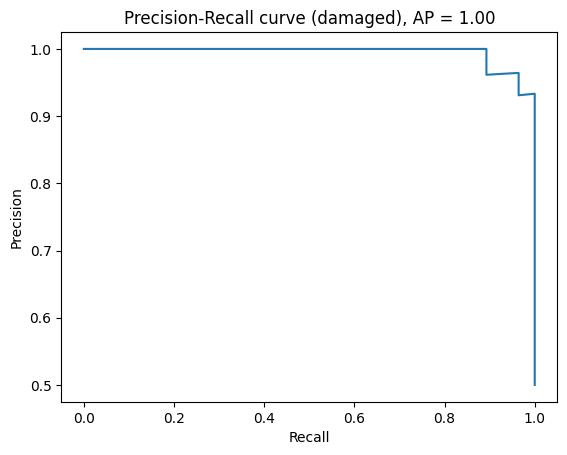

Chosen threshold: 0.604
Precision at this threshold: 0.964
Recall at this threshold: 0.964


In [5]:
import os
os.makedirs("assets", exist_ok=True)

# load the best saved model and get its answers on the val images
model.load_state_dict(torch.load("resnet18_best.pth"))
_, vp, vy = run_epoch(val_dl, False)
y_true = (vy == 0).astype(int)      # 1 = damaged

prec, rec, thr = precision_recall_curve(y_true, vp)
ap = average_precision_score(y_true, vp)

plt.plot(rec, prec)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision-Recall curve (damaged), AP = {ap:.2f}")
plt.savefig("assets/pr_curve.png", dpi=150)
plt.show()

# pick a threshold that catches at least 90% of damaged items
ok = np.where(rec[:-1] >= 0.90)[0]
best_i = ok[np.argmax(prec[:-1][ok])]
chosen_thr = thr[best_i]
print("Chosen threshold:", round(chosen_thr, 3))
print("Precision at this threshold:", round(prec[best_i], 3))
print("Recall at this threshold:", round(rec[best_i], 3))

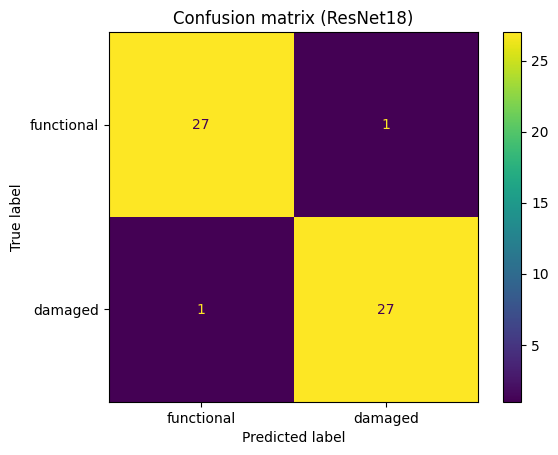

              precision    recall  f1-score   support

  functional       0.96      0.96      0.96        28
     damaged       0.96      0.96      0.96        28

    accuracy                           0.96        56
   macro avg       0.96      0.96      0.96        56
weighted avg       0.96      0.96      0.96        56

F1 (damaged): 0.964


In [6]:
pred = (vp >= chosen_thr).astype(int)

cm = confusion_matrix(y_true, pred)
ConfusionMatrixDisplay(cm, display_labels=["functional", "damaged"]).plot()
plt.title("Confusion matrix (ResNet18)")
plt.savefig("assets/confusion_matrix.png", dpi=150)
plt.show()

print(classification_report(y_true, pred, target_names=["functional", "damaged"]))
print("F1 (damaged):", round(f1_score(y_true, pred), 3))

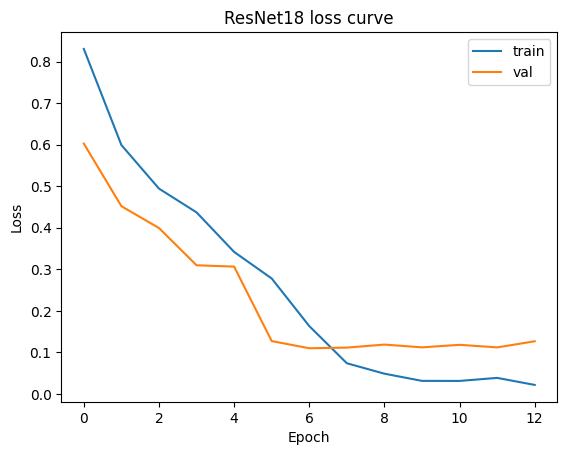

In [7]:
plt.plot(train_losses, label="train")
plt.plot(val_losses, label="val")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.title("ResNet18 loss curve")
plt.savefig("assets/resnet_loss_curve.png", dpi=150)
plt.show()

In [11]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [12]:
# baseline used 128x128 images and mean/std of 0.5
base_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)])
base_dl = DataLoader(datasets.ImageFolder("data/val", base_tf), batch_size=16)

baseline = BaselineCNN().to(device)      # <- use your class name
baseline.load_state_dict(torch.load("models/baseline_cnn_best.pth", map_location=device))
baseline.eval()

bp, bl = [], []
with torch.no_grad():
    for x, y in base_dl:
        out = baseline(x.to(device))
        bp += torch.softmax(out, 1)[:, 0].cpu().tolist()   # chance of "damaged"
        bl += y.tolist()
bp = np.array(bp)
b_true = (np.array(bl) == 0).astype(int)

def scores(true, probs, thr):
    p = (probs >= thr).astype(int)
    tp = ((p == 1) & (true == 1)).sum()
    return {
        "Accuracy":  round((p == true).mean(), 3),
        "Precision": round(tp / max(p.sum(), 1), 3),
        "Recall":    round(tp / max(true.sum(), 1), 3),
        "F1":        round(f1_score(true, p), 3),
        "AP":        round(average_precision_score(true, probs), 3)}

base_s   = scores(b_true, bp, 0.5)
resnet_s = scores(y_true, vp, chosen_thr)
print("Baseline:", base_s)
print("ResNet18:", resnet_s)

Baseline: {'Accuracy': np.float64(0.696), 'Precision': np.float64(0.704), 'Recall': np.float64(0.679), 'F1': 0.691, 'AP': np.float64(0.787)}
ResNet18: {'Accuracy': np.float64(0.964), 'Precision': np.float64(0.964), 'Recall': np.float64(0.964), 'F1': 0.964, 'AP': np.float64(0.995)}


In [13]:
os.makedirs("reports", exist_ok=True)

report = f"""# Training Report: Task 2 (Transfer Learning)

Damaged is the positive class. Validation set: {len(y_true)} images.

| Model | Accuracy | Precision | Recall | F1 | AP |
|---|---|---|---|---|---|
| Baseline CNN (threshold 0.5) | {base_s['Accuracy']} | {base_s['Precision']} | {base_s['Recall']} | {base_s['F1']} | {base_s['AP']} |
| ResNet18 transfer (threshold {chosen_thr:.2f}) | {resnet_s['Accuracy']} | {resnet_s['Precision']} | {resnet_s['Recall']} | {resnet_s['F1']} | {resnet_s['AP']} |

Pictures: assets/pr_curve.png, assets/confusion_matrix.png, assets/resnet_loss_curve.png

Notes:
- ResNet18 trained in 2 rounds: last layer only (5 epochs), then last block too (8 epochs).
- Augmentation: random crop, flip, rotation, colour change (train images only).
- Class weights used in the loss. Data is balanced now, but real club photos will not be.
- Threshold {chosen_thr:.2f} chosen so recall stays at or above 90%, because missing damaged equipment is the costly mistake.
- Validation set is small, so scores can change by a few points between runs.
"""
open("reports/training_report.md", "w").write(report)

decisions = f"""# Decision Log

## Why ResNet18 instead of the custom CNN
- The custom CNN overfit: about 92% train accuracy but only about 69.6% on validation. With 220 training images it cannot learn good features from scratch.
- ResNet18 already learned edges, textures and shapes from millions of ImageNet photos, so it only needs to learn the last step: functional or damaged.
- Result on the same validation images: F1 {base_s['F1']} (baseline) vs {resnet_s['F1']} (ResNet18).
- ResNet18 is small and fast, which suits deployment on Hugging Face Spaces in Task 3.

## Other choices
- Precision-recall curve instead of accuracy: the club must not miss damaged equipment.
- Class-weighted loss: damaged items will be rarer in real use.
- Two-round training with a small learning rate for the pre-trained block, so it does not forget what it knew.
"""
open("DECISIONS.md", "w").write(decisions)
print(report)

# Training Report: Task 2 (Transfer Learning)

Damaged is the positive class. Validation set: 56 images.

| Model | Accuracy | Precision | Recall | F1 | AP |
|---|---|---|---|---|---|
| Baseline CNN (threshold 0.5) | 0.696 | 0.704 | 0.679 | 0.691 | 0.787 |
| ResNet18 transfer (threshold 0.60) | 0.964 | 0.964 | 0.964 | 0.964 | 0.995 |

Pictures: assets/pr_curve.png, assets/confusion_matrix.png, assets/resnet_loss_curve.png

Notes:
- ResNet18 trained in 2 rounds: last layer only (5 epochs), then last block too (8 epochs).
- Augmentation: random crop, flip, rotation, colour change (train images only).
- Class weights used in the loss. Data is balanced now, but real club photos will not be.
- Threshold 0.60 chosen so recall stays at or above 90%, because missing damaged equipment is the costly mistake.
- Validation set is small, so scores can change by a few points between runs.



In [14]:
print("ResNet18 F1:", resnet_s["F1"], "| target: above 0.85")

ResNet18 F1: 0.964 | target: above 0.85


In [15]:
!zip -r results.zip assets reports DECISIONS.md
from google.colab import files
files.download("results.zip")

  adding: assets/ (stored 0%)
  adding: assets/confusion_matrix.png (deflated 19%)
  adding: assets/pr_curve.png (deflated 24%)
  adding: assets/resnet_loss_curve.png (deflated 10%)
  adding: reports/ (stored 0%)
  adding: reports/training_report.md (deflated 43%)
  adding: DECISIONS.md (deflated 42%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>